In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ModuleNotFoundError: No module named 'tqdm'

In [ ]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [ ]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [ ]:
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
numerical_columns = list(df.dtypes[df.dtypes != 'str'].index)

categorical_columns

['lead_source', 'industry', 'employment_status', 'location']

In [ ]:
for c in categorical_columns:
    df[c] = df[c].fillna('NA')

for c in numerical_columns:
    df[c] = df[c].fillna(0.0)

In [ ]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [ ]:
y_full_train = df_full_train.converted.values
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

len(y_full_train), len(y_train), len(y_val), len(y_test)

(4000, 3000, 1000, 1000)

In [ ]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [ ]:
auc_score = {}
numerical_columns_train = list(df_train.dtypes[df_train.dtypes != 'str'].index)

for c in numerical_columns_train:
    auc = roc_auc_score(y_train, df_train[c])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])

    auc_score[c] = auc

In [ ]:
for key, value in auc_score.items():
    print(f'{key}: {value}')

annual_income: 0.6081977776250831
number_of_courses_viewed: 0.7229894623989618
interaction_count: 0.7649203047563227
lead_score: 0.7882254810906102


In [ ]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical_columns + numerical_columns_train].to_dict(orient='records')
x_train = dv.fit_transform(train_dict)

In [ ]:
val_dict = df_val[categorical_columns + numerical_columns_train].to_dict(orient='records')
x_val = dv.transform(val_dict)

In [ ]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(x_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [ ]:
y_pred = model.predict_proba(x_val)[:,1]

auc = round(roc_auc_score(y_val, y_pred),3)

auc

0.732

In [ ]:
scores = []

thresholds = np.linspace(0,1,101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, tn, fp, fn))

columns = ['threshold', 'tp', 'tn', 'fp', 'fn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

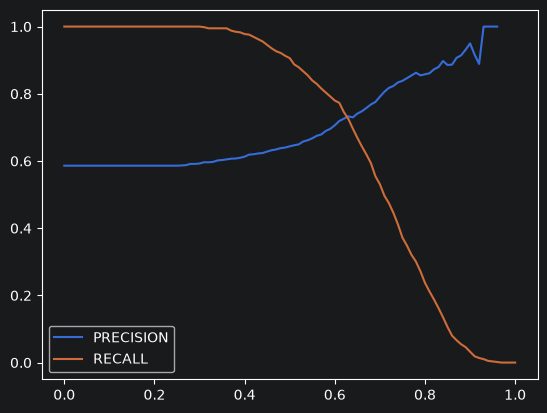

In [ ]:
plt.plot(df_scores.threshold, df_scores.precision, label='PRECISION')
plt.plot(df_scores.threshold, df_scores.recall, label='RECALL')
plt.legend()

In [ ]:
df_scores['F1'] = 2*((df_scores.precision * df_scores.recall) / (df_scores.precision + df_scores.recall))

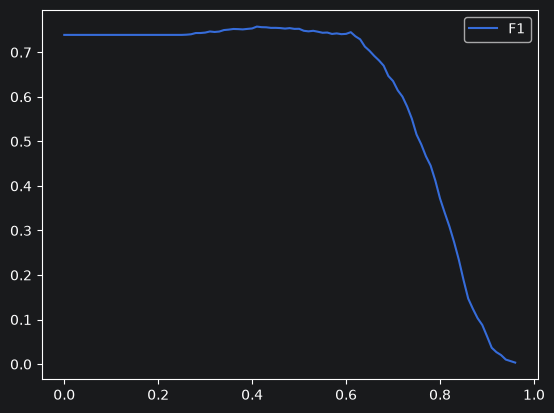

In [ ]:
plt.plot(df_scores.threshold, df_scores.F1, label='F1')
plt.legend()

In [ ]:
df_scores.loc[df_scores['F1'].idxmax()][['threshold', 'F1']]

threshold    0.410000
F1           0.757616
Name: 41, dtype: float64

In [ ]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical_columns + numerical_columns_train].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    x_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(x_train, y_train)

    return dv, model

In [ ]:
def predict(df, dv, model):
    dicts = df[categorical_columns + numerical_columns_train].to_dict(orient='records')

    x_val_ = dv.transform(dicts)
    y_pred = model.predict_proba(x_val_)[:,1]

    return y_pred

In [ ]:
n_split = 5

kfold = KFold(n_splits=n_split, shuffle=True, random_state=1)
scores_1 = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_ = df_full_train.iloc[train_idx]
    df_val_ = df_full_train.iloc[val_idx]

    y_train = df_train_.converted.values
    y_val = df_val_.converted.values

    dv, model = train(df_train_, y_train)
    y_pred = predict(df_val_, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores_1.append(auc)

print(f'Score Mean = {round(np.mean(scores_1),3)} : std = {round(np.std(scores_1),3)}')



D:\Programmation\PythonProjects\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
D:\Programmation\PythonProjects\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

Score Mean = 0.791 : std = 0.013


D:\Programmation\PythonProjects\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
n_split = 5

for C in tqdm([0.000001, 0.001, 1]):

    kfold = KFold(n_splits=n_split, shuffle=True, random_state=1)
    scores_1 = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_ = df_full_train.iloc[train_idx]
        df_val_ = df_full_train.iloc[val_idx]

        y_train = df_train_.converted.values
        y_val = df_val_.converted.values

        dv, model = train(df_train_, y_train, C=C)
        y_pred = predict(df_val_, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores_1.append(auc)

    print(f'C = {C} | Score Mean = {round(np.mean(scores_1),3)} : std = {round(np.std(scores_1),3)}')

 33%|███▎      | 1/3 [00:01<00:03,  1.93s/it]

C = 1e-06 | Score Mean = 0.615 : std = 0.019


 67%|██████▋   | 2/3 [00:04<00:02,  2.31s/it]

C = 0.001 | Score Mean = 0.783 : std = 0.013


D:\Programmation\PythonProjects\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
D:\Programmation\PythonProjects\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

C = 1 | Score Mean = 0.791 : std = 0.013
